# 评估

In [1]:
import torch

/home/heyiran/.conda/envs/HWsim/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import os, sys, itertools
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..')))
from hw2vec.config import Config
from hw2vec.hw2graph import *
from tqdm import tqdm

In [3]:
dir = ['--yaml_path', '../config/example_gnn4ip.yaml', \
    #    '--raw_dataset_path', '../../bigcreate/newdatas', \
       '--data_pkl_path', 'pkl/dfg_ip_rt291.pkl', \
        '--graph_type', 'DFG']
cfg = Config(dir)

In [4]:
cfg.num_feature_dim = 37

## 1 加载模型

In [5]:
model = GRAPH2VEC(cfg)

convs = [
        GRAPH_CONV("gcn", 37, cfg.hidden),#前者是标签数量，后者是隐藏层
        GRAPH_CONV("gcn", cfg.hidden, cfg.hidden),
        GRAPH_CONV("gcn", cfg.hidden, cfg.hidden)
    ]
model.set_graph_conv(convs)

pool = GRAPH_POOL("sagpool", cfg.hidden, cfg.poolratio)
model.set_graph_pool(pool)

readout = GRAPH_READOUT("mean")
model.set_graph_readout(readout)

output = nn.Linear(cfg.hidden, cfg.embed_dim)
model.set_output_layer(output)

In [6]:
output = nn.Linear(cfg.hidden, cfg.embed_dim)
model.set_node_output_layer(output)

output = nn.Linear(cfg.hidden,cfg.hidden,bias=False)
model.set_attention_output_layer(output)#
# print(model.last_fc)
# exit(0)
output = [nn.Linear(cfg.hidden*3*2, cfg.hidden*2),
            nn.Linear(cfg.hidden*2,cfg.hidden),
            nn.Linear(cfg.hidden,int(cfg.hidden/2)),
            nn.Linear(int(cfg.hidden/2),1)
        #   nn.Linear(cfg.embed_dim, 1)
            ]
model.new_set_output_layer(output)

In [7]:
model.load_state_dict(torch.load("modelparam/hw2vec.pth"))

RuntimeError: Error(s) in loading state_dict for GRAPH2VEC:
	Missing key(s) in state_dict: "pool1.graph_pool.select.weight". 
	size mismatch for bn.module.weight: copying a param with shape torch.Size([384]) from checkpoint, the shape in current model is torch.Size([768]).
	size mismatch for bn.module.bias: copying a param with shape torch.Size([384]) from checkpoint, the shape in current model is torch.Size([768]).
	size mismatch for bn.module.running_mean: copying a param with shape torch.Size([384]) from checkpoint, the shape in current model is torch.Size([768]).
	size mismatch for bn.module.running_var: copying a param with shape torch.Size([384]) from checkpoint, the shape in current model is torch.Size([768]).
	size mismatch for layers.0.graph_conv.bias: copying a param with shape torch.Size([64]) from checkpoint, the shape in current model is torch.Size([128]).
	size mismatch for layers.0.graph_conv.lin.weight: copying a param with shape torch.Size([64, 37]) from checkpoint, th

In [8]:
cfg.device = 'cuda'
model.to(cfg.device)
trainer = PairwiseGraphTrainer(cfg)
trainer.build(model)

## 2 测试数据

In [9]:
all_pairs = torch.load("all_pairs.pt")

In [10]:
labels = []
for i in range(len(all_pairs)):
    labels.append(all_pairs[i][2])
labels = torch.tensor(labels)

In [11]:
labels

tensor([-1, -1, -1,  ..., -1, -1, -1])

In [12]:
len(labels)

42195

In [13]:
data_proc = DataProcessor(cfg)

In [14]:
train_pairs, test_pairs = data_proc.split_dataset(cfg.ratio, cfg.seed, all_pairs)
train_loader = DataLoader(train_pairs, shuffle=True, batch_size=cfg.batch_size)
test_loader  = DataLoader(test_pairs, shuffle=True, batch_size=cfg.batch_size)

重复数据打包数据会使batch顺序改变？总的结果好像并没有变？

分析下来，感觉最可能的原因是验证集与测试集的划分每次都一样？导致测试集中的样例一直是那些个？基本石锤，与`train_test_split`中的`random_state`相关，造成的结果是每次划分的都相同

Batch打包的时候有随机？所以`outputs`会有变化

## 3 评估

主要是想实现对AUC的评估（其余指标都是现成的）

In [15]:
test_loss, test_labels, primitive_outputs, test_preds = trainer.inference(test_loader)

  0%|          | 0/264 [00:00<?, ?it/s]


IndexError: Dimension out of range (expected to be in range of [-1, 0], but got -2)

In [16]:
test_labels

NameError: name 'test_labels' is not defined

In [17]:
primitive_outputs

NameError: name 'primitive_outputs' is not defined

In [23]:
trainer.metric_calc(test_loss,  test_labels,  test_preds,  header="test ")

test  loss: 0.015974, test  accuracy: 0.9146, test  f1 score: 0.7180, test  confusion_matrix: [[6800  668], [  53  918]], test  precision: 0.5788, test  recall: 0.9454


In [17]:
trainer.metric_print(trainer.min_test_loss, **trainer.metrics, header="best ")

best  loss: 0.015974, best  accuracy: 0.9146, best  f1 score: 0.7180, best  confusion_matrix: [[6800  668], [  53  918]], best  precision: 0.5788, best  recall: 0.9454


In [17]:
auc = roc_auc_score(test_labels, primitive_outputs)

In [18]:
auc

0.9745914873594553

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

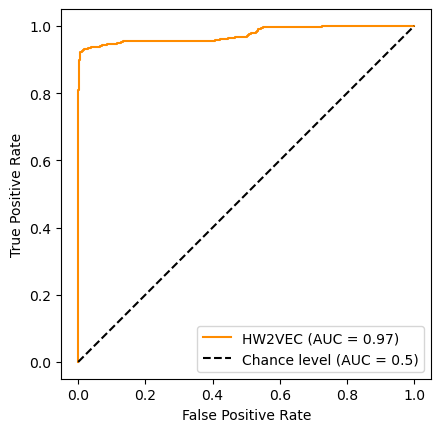

In [20]:
RocCurveDisplay.from_predictions(
    test_labels,
    primitive_outputs,
    name=f"HW2VEC",
    color="darkorange",
    plot_chance_level=True,
)
plt.axis("square")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
# plt.title("One-vs-Rest ROC curves:\nVirginica vs (Setosa & Versicolor)")
plt.legend()
plt.show()

```
plot_chance_levelbool, default=False
Whether to plot the chance level.

New in version 1.3.
```
更新一下`scikit-learn`包：

```
(HW2VEC) PS C:\Users\blahblah> pip install --upgrade scikit-learn
Requirement already satisfied: scikit-learn in e:\programdata\miniconda3\envs\hw2vec\lib\site-packages (1.2.2)
Collecting scikit-learn
  Downloading scikit_learn-1.3.1-cp310-cp310-win_amd64.whl (9.3 MB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 511.3 kB/s eta 0:00:00
Requirement already satisfied: numpy<2.0,>=1.17.3 in e:\programdata\miniconda3\envs\hw2vec\lib\site-packages (from scikit-learn) (1.23.5)
Requirement already satisfied: scipy>=1.5.0 in e:\programdata\miniconda3\envs\hw2vec\lib\site-packages (from scikit-learn) (1.10.1)
Requirement already satisfied: joblib>=1.1.1 in e:\programdata\miniconda3\envs\hw2vec\lib\site-packages (from scikit-learn) (1.2.0)
Requirement already satisfied: threadpoolctl>=2.0.0 in e:\programdata\miniconda3\envs\hw2vec\lib\site-packages (from scikit-learn) (3.1.0)
Installing collected packages: scikit-learn
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.2.2
    Uninstalling scikit-learn-1.2.2:
      Successfully uninstalled scikit-learn-1.2.2
Successfully installed scikit-learn-1.3.1
```

搞错了把本地的更新了，笑死

In [21]:
trainer.evaluate(cfg.epochs, train_loader, test_loader)

 77%|███████▋  | 1617/2110 [31:06<09:29,  1.15s/it] 


KeyboardInterrupt: 